# P1. Classification on Cats vs Dogs dataset

Task: load the cats vs dogs dataset, write a simple neural network to perform classification over the two classes, test the network and plot the results for each class.

![Animals-10](https://storage.googleapis.com/kaggle-datasets-images/59760/115796/95649e825d9344084af2a24012c4d072/dataset-cover.jpg?t=2018-10-05-08-07-40)

## Task 0: Import libraries ✅

All the libraries in this section should be enough for the project. If you want to, you can import more libraries.

In [ ]:
# We need to first install PyTorch Lightning, since it's not included in Python
!pip install pytorch-lightning

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 852.4/852.4 kB 32.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 41.1 MB/s eta 0:00:00


In [ ]:
# Matplotlib for plotting, numpy for math operations
from matplotlib import pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score, matthews_corrcoef

# PyTorch Lightning ⚡ to define our neural network
import torch
import torch.nn as nn
from torch.nn import functional as F
import pytorch_lightning as pl
from pytorch_lightning import LightningModule, Trainer
from pytorch_lightning.callbacks.early_stopping import EarlyStopping

# Dataloader and torchvision to define our input dataset
from torch.utils.data import random_split, DataLoader
from torchvision.datasets import ImageFolder
from torchvision import transforms

# Torchmetrics to monitor metrics (classification accuracy)
from torchmetrics.functional.classification.accuracy import accuracy

#useful
import os
import shutil
import random
from pathlib import Path
import pandas as pd

## Task 1: Download/Import Dataset 📃
Link full dataset: https://www.kaggle.com/datasets/alinasir1596/catvsdog-small-dataset?resource=download

Link local version: https://drive.google.com/file/d/1KLwUcMDodGiioqODrczIQZpU7Jw4qgxi/view?usp=share_link

The dataset is in MyDrive/Copia di dogs-vs-cat-small.zip.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#unzip archive.zip
!rm -r dogs-vs-cat-small
!unzip "drive/MyDrive/Copia di dogs-vs-cat-small.zip"

Output streaming troncato alle ultime 5000 righe.
  inflating: dogs-vs-cat-small/train/dogs/dog.496.jpg  
  inflating: __MACOSX/dogs-vs-cat-small/train/dogs/._dog.496.jpg  
  inflating: dogs-vs-cat-small/train/dogs/dog.125.jpg  
  inflating: __MACOSX/dogs-vs-cat-small/train/dogs/._dog.125.jpg  
  inflating: dogs-vs-cat-small/train/dogs/dog.8.jpg  
  inflating: __MACOSX/dogs-vs-cat-small/train/dogs/._dog.8.jpg  
  inflating: dogs-vs-cat-small/train/dogs/dog.48.jpg  
  inflating: __MACOSX/dogs-vs-cat-small/train/dogs/._dog.48.jpg  
  inflating: dogs-vs-cat-small/train/dogs/dog.643.jpg  
  inflating: __MACOSX/dogs-vs-cat-small/train/dogs/._dog.643.jpg  
  inflating: dogs-vs-cat-small/train/dogs/dog.657.jpg  
  inflating: __MACOSX/dogs-vs-cat-small/train/dogs/._dog.657.jpg  
  inflating: dogs-vs-cat-small/train/dogs/dog.131.jpg  
  inflating: __MACOSX/dogs-vs-cat-small/train/dogs/._dog.131.jpg  
  inflating: dogs-vs-cat-small/train/dogs/dog.119.jpg  
  inflating: __MACOSX/dogs-vs-cat-small

## Task 1: Define parameters and hyperparameters 📃


*   **Learning rate** - how fast does our network learn? (Warning, do not set too high)
*   **Batch size** - how many samples does the network "see" at every iteration (usually, the bigger the better)
*   **Dataset size** - how many samples are in the whole dataset? (train + validation)
*   **Train size** - how many samples are in the training dataset?
*   **Val size** - how many samples are in the validation dataset?
*   **Input width** - how wide (in pixels) is our input image? (must be square images)
*   **Input height** - how tall (in pixels) is our input image? (must be square images)
*   **Input channels** - how many channels does the input image have?
*   **Mean** - dataset mean
*   **Std** - dataset standard variance
*   **Hidden dim** - how many neurons are there in the hidden layer?
*   **Num classes** - how many classes (digits) do we want to classify in our dataset?





In [ ]:
# Manual Transform the dataset to have all the images of the same size
manual_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

In [ ]:
pathData = "dogs-vs-cat-small"

batch_size = 32

# to load the dataset
dataset = ImageFolder(root=pathData, transform=manual_transform)

#data of the data
dataset_size = len(dataset)
input_width = 224
input_height = 224
input_channels = 3
num_classes = 2

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

#data of the training
trainSize = 0.8
valSize = 0.1
testSize = 1-trainSize-valSize
train_sizeDataset = dataset_size*trainSize
val_sizeDataset = dataset_size*valSize
testSizeDataset = dataset_size-train_sizeDataset-val_sizeDataset

learning_rateDefault = 0.0002

transformsDefault = transforms.Compose([transforms.Resize((input_width,input_height)),transforms.ToTensor(),transforms.Normalize(mean,std)])

print("Data sizes:\ndataset: {},\ntrain: {},\nval: {},\ntest {}".format(dataset_size, train_sizeDataset, val_sizeDataset, testSizeDataset))

#data of the model
hidden_dimDefault = [128,128,128]

#assert train_size + val_size == dataset_size, "Oh no! The sum of the train and validation sets must be equal the whole dataset size!"
#assert input_width == input_height, "Oh no! The input width should be the same as the input height!"


Data sizes:
dataset: 4000,
train: 3200.0,
val: 400.0,
test 400.0


Creating a function to show the accuracy during training.

In [ ]:
def showAccuracyInTraining(model,title):
  ta = [float(i) for i in model.trainAccuracy]
  te = model.trainEpochs
  va = [float(i) for i in model.validationAccuracy]
  ve = model.validationEpochs

  plt.plot(torch.linspace(0,1,len(ta)),ta,label="Train accuracy")
  plt.plot(torch.linspace(0,1,len(va)),va,label="Validation accuracy")
  for i in set(te): plt.fill_between(torch.linspace(0,1,len(te)),0,0.5,where=((torch.asarray(te)==i) | (torch.asarray(te[1:]+[0])==i)),alpha=0.2)
  for i in set(ve): plt.fill_between(torch.linspace(0,1,len(ve)),0.5,1,where=((torch.asarray(ve)==i) | (torch.asarray(ve[1:]+[0])==i)),alpha=0.2)
  plt.title(title)
  plt.ylabel("Accuracy")
  plt.legend()
  plt.savefig("{}.png".format(title),dpi=300)
  plt.show()

## Task 2: Define the DataModule 📃

In [ ]:
class MyCustomDataModule(pl.LightningDataModule):
    def __init__(self, trainSize, valSize, data_dir: str = "./", transform = transformsDefault):
        super().__init__()
        self.data_dir = data_dir
        self.transform = transform
        self.trainSize = trainSize
        self.valSize = valSize

        self.sizes = {}
        self.getDataset()

    def getDataset(self):
      #change the photo position inside the folder, to dynamic choice of the proporion of train and test
      path = Path(self.data_dir)
      dogs = list(path.rglob("*/dogs/*"))
      cats = list(path.rglob("*/cats/*"))

      self.sizes["trainSSum"] = 0
      self.sizes["valSSum"] = 0
      self.sizes["testSSum"] = 0

      #get number of photos for train, validation and test
      trainS = round(len(dogs)*self.trainSize)
      valS = round(len(dogs)*self.valSize)
      testS = len(dogs) - trainS - valS
      self.sizes["trainSSum"] += trainS
      self.sizes["valSSum"] += valS
      self.sizes["testSSum"] += testS
      train, validation, test = random_split(dogs, [trainS, valS, testS])
      #move photo
      for i in dogs:
        try:
          if i in train: shutil.move(i,path/"train/dogs")
          if i in validation: shutil.move(i,path/"validation/dogs")
          else: shutil.move(i,path/"test/dogs")
        except Exception as e: pass

      #get number of photos for train, validation and test
      trainS = round(len(cats)*self.trainSize)
      valS = round(len(cats)*self.valSize)
      testS = len(cats) - trainS - valS
      self.sizes["trainSSum"] += trainS
      self.sizes["valSSum"] += valS
      self.sizes["testSSum"] += testS
      train, validation, test = random_split(cats, [trainS, valS, testS])
      #move photo
      for i in cats:
        try:
          if i in train: shutil.move(i,path/"train/cats")
          if i in validation: shutil.move(i,path/"validation/cats")
          else: shutil.move(i,path/"test/cats")
        except Exception as e: pass

      print("Data size: train ({}), validation ({}), test ({})".format(self.sizes["trainSSum"], self.sizes["valSSum"], self.sizes["testSSum"]))

    def setup(self, stage = None):
        # Assign train/val datasets for use in dataloaders
        if stage == "fit" or stage is None:
          datasetTrain = ImageFolder(root="{}/train".format(self.data_dir), transform=self.transform)
          datasetValidation = ImageFolder(root="{}/validation".format(self.data_dir), transform=self.transform)
          self.dataset_train, self.dataset_val = datasetTrain, datasetValidation

        # Assign test dataset for use in dataloader(s)
        if stage == "test" or stage is None:
            datasetTest = ImageFolder(root="{}/test".format(self.data_dir), transform=self.transform)
            self.dataset_test = datasetTest

    def train_dataloader(self):
        return DataLoader(self.dataset_train, batch_size=batch_size,shuffle=True)

    def val_dataloader(self):
        return DataLoader(self.dataset_val, batch_size=batch_size)

    def test_dataloader(self):
        return DataLoader(self.dataset_test, batch_size=batch_size)

## Task 3: Define the neural network 📃


In [ ]:
class MLP(LightningModule):
    def __init__(self, learningRate = learning_rateDefault, hidden_dim = hidden_dimDefault):
        super().__init__()

        self.learningRate = learningRate

        #store to get measuraments
        self.ground_truth = []
        self.predictions = []

        self.trainAccuracy = []
        self.trainEpochs = []
        self.validationAccuracy = []
        self.validationEpochs = []

        #make model
        self.model = nn.Sequential(
              nn.Flatten(),
              nn.Linear(input_channels*input_width*input_height,hidden_dim[0]),
              nn.ReLU(),
              nn.Dropout(0.1),
              nn.Linear(hidden_dim[0],hidden_dim[1]),
              nn.ReLU(),
              nn.Dropout(0.1),
              nn.Linear(hidden_dim[1],hidden_dim[2]),
              nn.ReLU(),
              nn.Dropout(0.1),
              nn.Linear(hidden_dim[2],num_classes)
        )

    def forward(self, x):
        x = self.model(x)
        return x

    def training_step(self, batch, batch_nb):
        x, y = batch
        x = self(x)
        loss = F.cross_entropy(x,y)

        #get accuracy
        preds = torch.argmax(x, dim=1)
        acc = accuracy(preds, y, task="multiclass", num_classes=num_classes)

        self.trainAccuracy.append(acc)
        self.trainEpochs.append(self.current_epoch)

        self.log("train_loss", loss, prog_bar=True)
        self.log("train_acc", acc, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_nb):
        x, y = batch
        x = self(x)
        loss = F.cross_entropy(x,y)

        #get accuracy
        preds = torch.argmax(x, dim=1)
        acc = accuracy(preds, y, task="multiclass", num_classes=num_classes)

        self.validationAccuracy.append(acc)
        self.validationEpochs.append(self.current_epoch)

        self.log("val_loss",loss)
        self.log("val_acc",acc)

        return loss

    def test_step(self, batch, batch_nb):
        x, y = batch
        x = self(x)
        loss = F.cross_entropy(x,y)

        #get accuracy
        preds = torch.argmax(x, dim=1)
        acc = accuracy(preds, y, task="multiclass", num_classes=num_classes)

        #store to get measuraments
        self.ground_truth.append(y.data)     # Save ground truth
        self.predictions.append(preds.data)       # Save predictions

        # Calling self.log will surface up scalars for you in TensorBoard
        self.log("val_loss", loss, prog_bar=True)
        self.log("val_acc", acc, prog_bar=True)

        return loss

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.learningRate)

Testing various learning rate in order to find the best one.

In [ ]:
lrList = [0.0001,0.0002,0.001,0.002,0.01]

In [ ]:
resultLR = {}
modelsLR = {}
for i in lrList:
  #init model
  model = MLP(learningRate=i)

  #init module of data
  datamodule = MyCustomDataModule(trainSize,valSize,pathData)

  #init trainer
  trainer = Trainer(
      max_epochs= 4,
      callbacks=EarlyStopping(monitor="val_loss",patience=4,mode="min")
  )

  #train model
  trainer.fit(model, datamodule)

  #store results
  resultLR[i] = trainer.test(model, datamodule=datamodule)
  modelsLR[i] = model

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


Data size: train (3200), validation (400), test (400)


INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ Sequential │ 19.3 M │ train │     0 │
└───┴───────┴────────────┴────────┴───────┴───────┘

Trainable params: 19.3 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 19.3 M                                                                                               
Total estimated model params size (MB): 77.204                                                                     
Modules in train mode: 12                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

...

Output()

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=4` reached.


INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          val_acc          │    0.4749999940395355     │
│         val_loss          │    0.6943770051002502     │
└───────────────────────────┴───────────────────────────┘

In [ ]:
#get results
pd.DataFrame({i:i2[0] for i,i2 in resultLR.items()})

,0.0001,0.0002,0.0010,0.0020,0.0100
val_loss,0.660039,0.679951,0.696267,0.666051,0.694377
val_acc,0.630000,0.595000,0.602500,0.612500,0.475000


Testing various network architectures in order to find the best one.

In [ ]:
hiddenDimList = [[64,64,64],[128,128,128],[256,256,256],[128,256,128]]

In [ ]:
resultsHD = {}
modelsHD = {}
for i in hiddenDimList:

  #init model
  model = MLP(learningRate=0.0001,hidden_dim=i)

  #init module of data
  datamodule = MyCustomDataModule(trainSize,valSize,pathData)

  #init trainer
  trainer = Trainer(max_epochs=2)

  #train model
  trainer.fit(model,datamodule)

  #store results
  resultsHD[str(i)] = trainer.test(model,datamodule=datamodule)
  modelsHD[str(i)] = model

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Data size: train (3200), validation (400), test (400)


┏━━━┳━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ Sequential │  9.6 M │ train │     0 │
└───┴───────┴────────────┴────────┴───────┴───────┘

Trainable params: 9.6 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 9.6 M                                                                                                
Total estimated model params size (MB): 38.569                                                                     
Modules in train mode: 12                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

...

Output()

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=2` reached.


INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          val_acc          │    0.5649999976158142     │
│         val_loss          │     0.722212016582489     │
└───────────────────────────┴───────────────────────────┘

In [ ]:
#get results
pd.DataFrame({i:i2[0] for i,i2 in resultsHD.items()})

,"[64, 64, 64]","[128, 128, 128]","[256, 256, 256]","[128, 256, 128]"
val_loss,0.71644,0.67053,0.724147,0.722212
val_acc,0.55000,0.63000,0.570000,0.565000


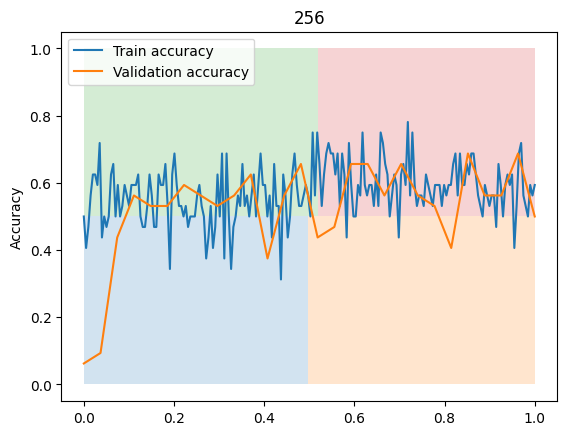

In [ ]:
showAccuracyInTraining(modelsHD[str(hiddenDimList[2])],"256")

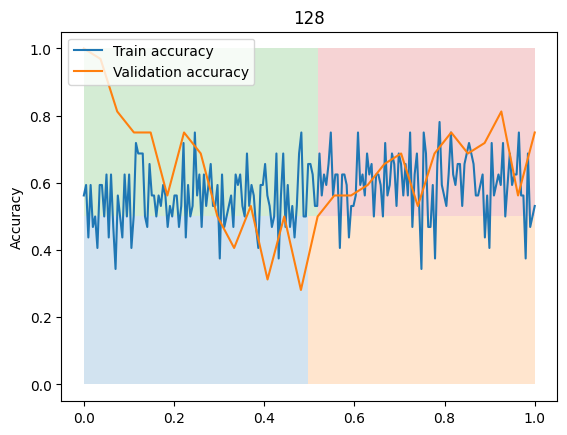

In [ ]:
showAccuracyInTraining(modelsHD[str(hiddenDimList[1])],"128")

Testing a different transforms of the input images.

In [ ]:
transformC1 = transforms.Compose([transforms.RandomHorizontalFlip(),transforms.RandomRotation(20),transforms.RandomResizedCrop(size=(input_width,input_height)),transforms.ToTensor(),transforms.Normalize(mean,std)])

#init model
modelT1 = MLP(learningRate=0.0001,hidden_dim=[128,128,128])

#init module of data
datamoduleT1 = MyCustomDataModule(trainSize,valSize,pathData,transform=transformC1)

#init trainer
trainerT1 = Trainer(max_epochs=8)

#train model
trainerT1.fit(modelT1,datamoduleT1)

#test model
resultT1 = trainerT1.test(modelT1,datamoduleT1)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Data size: train (3200), validation (400), test (400)


┏━━━┳━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ Sequential │ 19.3 M │ train │     0 │
└───┴───────┴────────────┴────────┴───────┴───────┘

Trainable params: 19.3 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 19.3 M                                                                                               
Total estimated model params size (MB): 77.204                                                                     
Modules in train mode: 12                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=8` reached.


INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          val_acc          │    0.5400000214576721     │
│         val_loss          │    0.7150348424911499     │
└───────────────────────────┴───────────────────────────┘

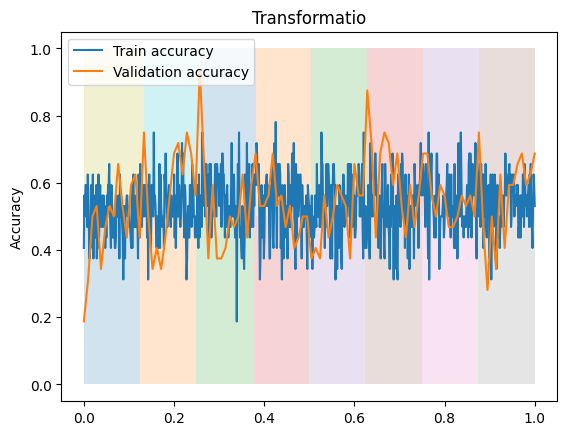

In [ ]:
showAccuracyInTraining(modelT1,"Transformatio")

In [ ]:
#get result
resultT1

[{'val_loss': 0.7150348424911499, 'val_acc': 0.5400000214576721}]

In [ ]:
transformC2 = transforms.Compose([transforms.RandomHorizontalFlip(0.2),transforms.RandomRotation(10),transforms.Resize((224,224)),transforms.ToTensor(),transforms.Normalize(mean,std)])

#init model
modelT2 = MLP(learningRate=0.0001,hidden_dim=[128,128,128])

#init module of data
datamoduleT2 = MyCustomDataModule(trainSize,valSize,pathData,transform=transformC2)

#init trainer
trainerT2 = Trainer(max_epochs=8)

#train model
trainerT2.fit(modelT2,datamoduleT2)

#test model
resultT2 = trainerT2.test(modelT2,datamoduleT2)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Data size: train (3200), validation (400), test (400)


┏━━━┳━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ Sequential │ 19.3 M │ train │     0 │
└───┴───────┴────────────┴────────┴───────┴───────┘

Trainable params: 19.3 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 19.3 M                                                                                               
Total estimated model params size (MB): 77.204                                                                     
Modules in train mode: 12                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=8` reached.


INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          val_acc          │    0.6000000238418579     │
│         val_loss          │    0.6451318860054016     │
└───────────────────────────┴───────────────────────────┘

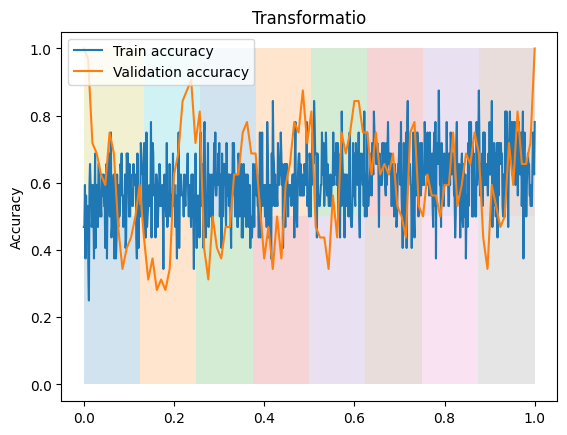

In [ ]:
showAccuracyInTraining(modelT2,"Transformatio")

In [ ]:
#get result
resultT2

[{'val_loss': 0.6451318860054016, 'val_acc': 0.6000000238418579}]

# Best model

In [ ]:
#set parameters
transform = transforms.Compose([transforms.Resize((input_width,input_height)),transforms.ToTensor(),transforms.Normalize(mean,std)])

hidden_dim = [128,128,128]

#init model
model = MLP(learningRate=0.0001,hidden_dim=hidden_dim)

#init module of data
datamodule = MyCustomDataModule(trainSize,valSize,pathData,transform=transform)

#init trainer
trainer = Trainer(max_epochs=4)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Data size: train (3200), validation (400), test (400)


## Task 4: Train 📃

In [ ]:
#train model
trainer.fit(model,datamodule)

INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ Sequential │ 19.3 M │ train │     0 │
└───┴───────┴────────────┴────────┴───────┴───────┘

Trainable params: 19.3 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 19.3 M                                                                                               
Total estimated model params size (MB): 77.204                                                                     
Modules in train mode: 12                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=4` reached.


## Task 5: Test ✅

In [ ]:
#test model
trainer.test(model, datamodule=datamodule)
yTest = [i2.cpu() for i in model.ground_truth for i2 in i]
y = [i2.cpu() for i in model.predictions for i2 in i]

INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          val_acc          │    0.6324999928474426     │
│         val_loss          │    0.6864628791809082     │
└───────────────────────────┴───────────────────────────┘

## Task 6: Show results and experiment with splits 📃

Show training accuracy and validation accuracy in each epoch.

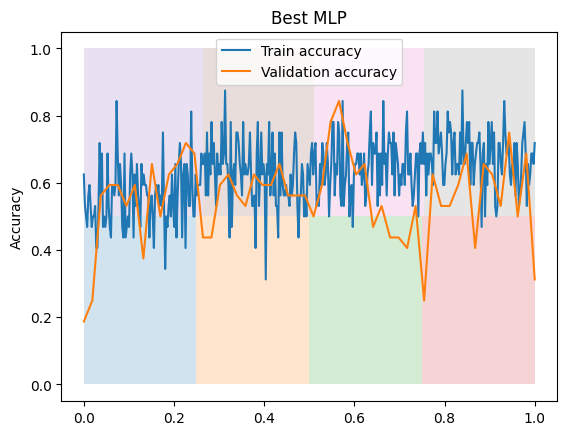

In [ ]:
showAccuracyInTraining(model,"Best MLP")

Get measuraments.

In [ ]:
accuracyR = accuracy_score(yTest,y)
precision = precision_score(yTest,y,average="macro")
recall = recall_score(yTest,y,average="macro")
f1Score = f1_score(yTest,y,average="macro")
balancedAccuracy = balanced_accuracy_score(yTest,y)
mccScore = matthews_corrcoef(yTest,y)

print("Accuracy: {}".format(accuracyR))
print("Precision: {}".format(precision))
print("recall: {}".format(recall))
print("f1 Score: {}".format(f1Score))
print("Balanced accuracy: {}".format(balancedAccuracy))
print("Metthews correlation coefficient: {}".format(mccScore))

Accuracy: 0.6325
Precision: 0.632768856935294
recall: 0.6325000000000001
f1 Score: 0.6323138588910635
Balanced accuracy: 0.6325000000000001
Metthews correlation coefficient: 0.2652687206884856


Bar plot of the predicted labels.

[[122  78]
 [ 69 131]]


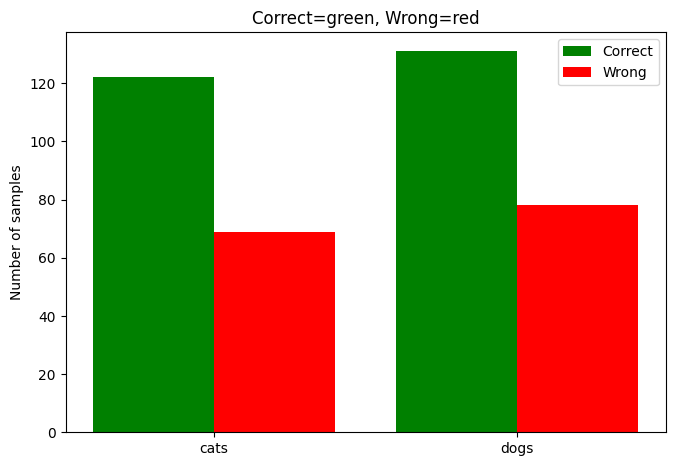

In [ ]:
confMatrix = confusion_matrix(yTest,y)

print(confMatrix)

# Use class names from the training dataset
class_names = ImageFolder("{}/train".format(pathData)).classes  # ['cats', 'dogs'] if folders are named that way
class_labels = np.arange(len(class_names))

correct = torch.asarray([confMatrix[0,0],confMatrix[1,1]])
wrong = torch.asarray([confMatrix[0,1],confMatrix[1,0]])

fig = plt.figure(figsize=(6, 4))
ax = fig.add_axes([0, 0, 1, 1], title='Correct=green, Wrong=red')

ax.bar(class_labels - 0.2, correct, width=0.4, color='g', label='Correct')
ax.bar(class_labels + 0.2, wrong,  width=0.4, color='r', label='Wrong')

ax.set_xticks(class_labels)
ax.set_xticklabels(class_names)
ax.set_ylabel("Number of samples")
ax.legend()
plt.show()


Cofusion matrix.

<Axes: >

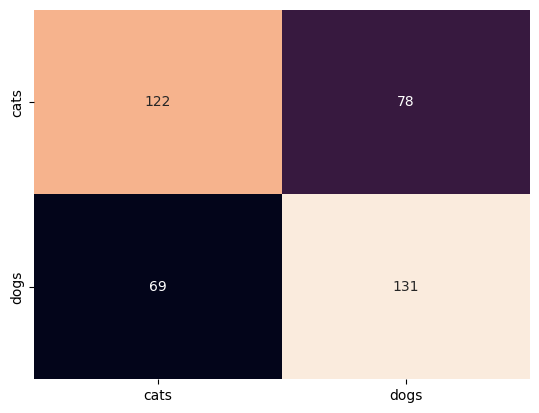

In [ ]:
sns.heatmap(confusion_matrix(yTest,y),annot=True,fmt="d",cbar=False,xticklabels=class_names,yticklabels=class_names)

# CNN

Building the model.

In [ ]:
class CNN(LightningModule):
    def __init__(self, learningRate):
        super().__init__()

        self.learningRate = learningRate

        self.ground_truth = []
        self.predictions = []

        self.trainAccuracy = []
        self.trainEpochs = []

        self.validationAccuracy = []
        self.validationEpochs = []

        self.model = nn.Sequential(
            nn.Conv2d(3,32,3,padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64,128,3,padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(128,256,3,padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Dropout(0.1),

            nn.Flatten(),
            nn.Linear(256*14*14,64),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(64,64),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(64,64),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(64,64),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(64,num_classes)
        )

    def forward(self, x):
        x = self.model(x)
        return x

    def training_step(self, batch, batch_nb):
        x, y = batch
        x = self(x)
        loss = F.cross_entropy(x,y)

        #get accuracy
        preds = torch.argmax(x, dim=1)
        acc = accuracy(preds, y, task="multiclass", num_classes=num_classes)

        self.trainAccuracy.append(acc)
        self.trainEpochs.append(self.current_epoch)

        self.log("train_loss", loss, prog_bar=True)
        self.log("train_acc", acc, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_nb):
        x, y = batch
        x = self(x)
        loss = F.cross_entropy(x,y)

        #get accuracy
        preds = torch.argmax(x, dim=1)
        acc = accuracy(preds, y, task="multiclass", num_classes=num_classes)

        self.validationAccuracy.append(acc)
        self.validationEpochs.append(self.current_epoch)

        self.log("val_loss", loss, prog_bar=True)
        self.log("val_acc", acc, prog_bar=True)
        return loss

    def test_step(self, batch, batch_nb):
        x, y = batch
        x = self(x)
        loss = F.cross_entropy(x,y)

        preds = torch.argmax(x, dim=1)
        acc = accuracy(preds, y, task="multiclass", num_classes=num_classes)

        self.ground_truth.append(y.data)     # Save ground truth
        self.predictions.append(preds.data)       # Save predictions

        # Calling self.log will surface up scalars for you in TensorBoard
        self.log("val_loss", loss, prog_bar=True)
        self.log("val_acc", acc, prog_bar=True)
        return loss

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.learningRate)

Testing different learning rate.

In [ ]:
lrList = [0.0001,0.0002,0.001,0.002,0.01]

In [ ]:
resultLRCNN = {}
modelsLRCNN = {}
for i in lrList:
  #init model
  model = CNN(learningRate=i)

  #init module of data
  datamodule = MyCustomDataModule(trainSize,valSize,pathData)

  #init trainer
  trainer = Trainer(
      max_epochs= 4,
      callbacks=EarlyStopping(monitor="val_loss",patience=4,mode="min")
  )

  #train model
  trainer.fit(model, datamodule)

  #store results
  resultLRCNN[i] = trainer.test(model, datamodule=datamodule)
  modelsLRCNN[i] = model

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Data size: train (3200), validation (400), test (400)


┏━━━┳━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ Sequential │  3.6 M │ train │     0 │
└───┴───────┴────────────┴────────┴───────┴───────┘

Trainable params: 3.6 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 3.6 M                                                                                                
Total estimated model params size (MB): 14.453                                                                     
Modules in train mode: 32                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

...

Output()

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=4` reached.


INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          val_acc          │    0.5350000262260437     │
│         val_loss          │    0.6882050037384033     │
└───────────────────────────┴───────────────────────────┘

In [ ]:
#get results
pd.DataFrame({i:i2[0] for i,i2 in resultLRCNN.items()})

,0.0001,0.0002,0.0010,0.0020,0.0100
val_loss,0.505545,0.47549,0.539059,0.596964,0.688205
val_acc,0.777500,0.76750,0.777500,0.692500,0.535000


Testing different transformations of the input images.

In [ ]:
transformC1CNN = transforms.Compose([transforms.RandomHorizontalFlip(),transforms.RandomRotation(20),transforms.RandomResizedCrop(size=(input_width,input_height)),transforms.ToTensor(),transforms.Normalize(mean,std)])

#init model
modelT1CNN = CNN(0.0001)

#init module of data
datamoduleT1CNN = MyCustomDataModule(trainSize,valSize,pathData,transform=transformC1CNN)

#init trainer
trainerT1CNN = Trainer(max_epochs=8)

#train model
trainerT1CNN.fit(modelT1CNN,datamoduleT1CNN)

#test model
resultsT1CNN = trainerT1CNN.test(modelT1CNN,datamoduleT1CNN)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Data size: train (3200), validation (400), test (400)


┏━━━┳━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ Sequential │  3.6 M │ train │     0 │
└───┴───────┴────────────┴────────┴───────┴───────┘

Trainable params: 3.6 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 3.6 M                                                                                                
Total estimated model params size (MB): 14.453                                                                     
Modules in train mode: 32                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=8` reached.


INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          val_acc          │           0.625           │
│         val_loss          │    0.6063584685325623     │
└───────────────────────────┴───────────────────────────┘

In [ ]:
#get result
resultsT1CNN

[{'val_loss': 0.6063584685325623, 'val_acc': 0.625}]

# Best model of CNN

Prepare model.

In [ ]:
#set parameters
transformCNN = transforms.Compose([transforms.Resize((input_width,input_height)),transforms.ToTensor(),transforms.Normalize(mean,std)])

#init model
modelCNN = CNN(0.0001)

#init module of data
datamoduleCNN = MyCustomDataModule(trainSize,valSize,pathData)

#init trainer
trainerCNN = Trainer(max_epochs=4)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Data size: train (3200), validation (400), test (400)


Train model.

In [ ]:
#train model
trainerCNN.fit(modelCNN,datamoduleCNN)

INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ Sequential │  3.6 M │ train │     0 │
└───┴───────┴────────────┴────────┴───────┴───────┘

Trainable params: 3.6 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 3.6 M                                                                                                
Total estimated model params size (MB): 14.453                                                                     
Modules in train mode: 32                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=4` reached.


Test model.

In [ ]:
#test model
resultsCNN = trainerCNN.test(modelCNN, datamodule=datamoduleCNN)
yTest = [i2.cpu() for i in modelCNN.ground_truth for i2 in i]
y = [i2.cpu() for i in modelCNN.predictions for i2 in i]

INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          val_acc          │    0.7900000214576721     │
│         val_loss          │    0.45096951723098755    │
└───────────────────────────┴───────────────────────────┘

Show results.

Show training accuracy and validation accuracy in each epoch.

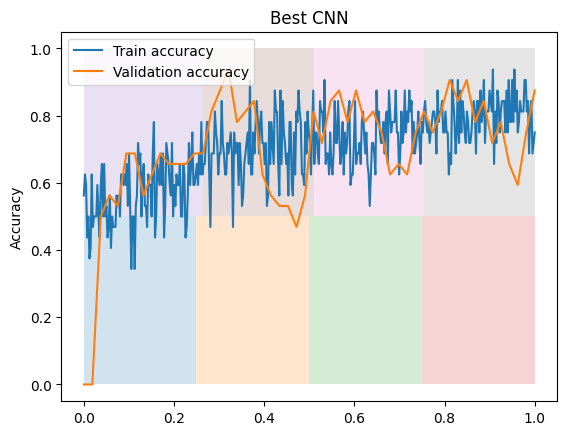

In [ ]:
showAccuracyInTraining(modelCNN,"Best CNN")

Get measuraments.

In [ ]:
accuracy = accuracy_score(yTest,y)
precision = precision_score(yTest,y,average="macro")
recall = recall_score(yTest,y,average="macro")
f1Score = f1_score(yTest,y,average="macro")
balancedAccuracy = balanced_accuracy_score(yTest,y)
mccScore = matthews_corrcoef(yTest,y)

print("Accuracy: {}".format(accuracy))
print("Precision: {}".format(precision))
print("recall: {}".format(recall))
print("f1 Score: {}".format(f1Score))
print("Balanced accuracy: {}".format(balancedAccuracy))
print("Metthews correlation coefficient: {}".format(mccScore))

Accuracy: 0.79
Precision: 0.7914279971862124
recall: 0.79
f1 Score: 0.7897424344822408
Balanced accuracy: 0.79
Metthews correlation coefficient: 0.5814262435907124


Bar plot of the predicted labels.

[[151  49]
 [ 35 165]]


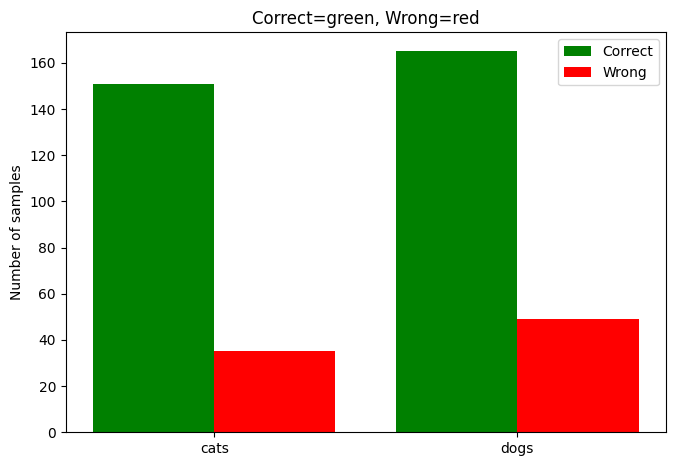

In [ ]:
confMatrix = confusion_matrix(yTest,y)

print(confMatrix)

# Use class names from the training dataset
class_names = ImageFolder("{}/train".format(pathData)).classes  # ['cats', 'dogs'] if folders are named that way
class_labels = np.arange(len(class_names))

correct = torch.asarray([confMatrix[0,0],confMatrix[1,1]])
wrong = torch.asarray([confMatrix[0,1],confMatrix[1,0]])

fig = plt.figure(figsize=(6, 4))
ax = fig.add_axes([0, 0, 1, 1], title='Correct=green, Wrong=red')

ax.bar(class_labels - 0.2, correct, width=0.4, color='g', label='Correct')
ax.bar(class_labels + 0.2, wrong,  width=0.4, color='r', label='Wrong')

ax.set_xticks(class_labels)
ax.set_xticklabels(class_names)
ax.set_ylabel("Number of samples")
ax.legend()
plt.show()


Confusion matrix.

<Axes: >

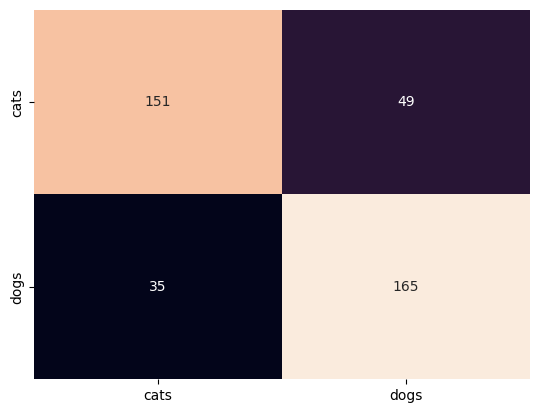

In [ ]:
sns.heatmap(confusion_matrix(yTest,y),annot=True,fmt="d",cbar=False,xticklabels=class_names,yticklabels=class_names)